# 词云

这里涉及到一个很重要的知识点，中文分词

1 首先安装jieba分词包

+ pip install jieba

2 然后做一个yes-minister的中文txt（yes_minister_cn），放在文件夹中

3 正式编程之前，还需要下载一个中文字体包，[地址是这个](https://s3-us-west-2.amazonaws.com/notion-static/b869cb0c7f4e4c909a069eaebbd2b7ad/simsun.ttf)。点击链接就直接下载了，文件名就是simsun.ttf

In [1]:
f_cn = open('yes_minister_cn.txt',encoding = 'GB18030') # mac电脑的编码是GB18030，windows可以改成utf-8

In [2]:
text_cn = f_cn.read()

In [3]:
f_cn.close()

In [4]:
text_cn[:50]

'本剧叙述在野党影子内阁成员Jim Hacker在帮助本党大选获胜之后担任行政事务部（DAA）部长的职'

下面这一段代码很重要了，就是分词

In [5]:
import jieba

In [6]:
text_cn_word = "/".join(jieba.cut(text_cn))

Building prefix dict from the default dictionary ...


Loading model from cache C:\Users\donganze\AppData\Local\Temp\jieba.cache


Loading model cost 0.365 seconds.


Prefix dict has been built successfully.


In [7]:
print(text_cn_word[:100])

本剧/叙述/在野党/影子内阁/成员/Jim/ /Hacker/在/帮助/本/党/大选/获胜/之后/担任/行政/事务部/（/DAA/）/部长/的/职务/，/从此/开始/与/以部/秘书/Sir/ /Hum


In [8]:
!pip install wordcloud

error: uv trampoline failed to spawn Python child process
  Caused by: permission denied (os error 5)



现在按照英文词云的套路text_cn进行分词，看看效果

In [9]:
from wordcloud import WordCloud  # 关键代码1

In [10]:
wordcloud = WordCloud().generate(text_cn_word) # 关键代码2

In [11]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [12]:
import matplotlib.pyplot as plt

(np.float64(-0.5), np.float64(399.5), np.float64(199.5), np.float64(-0.5))

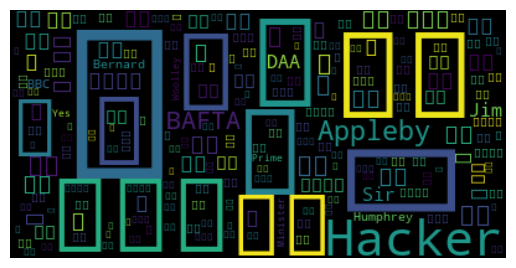

In [13]:
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

为什么会这样呢？

问题在哪里呢？这就需要我们之前下载的中文字体上场了，因为wordcloud默认的字体是英文的，中文就只有框框了

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


(np.float64(-0.5), np.float64(399.5), np.float64(199.5), np.float64(-0.5))

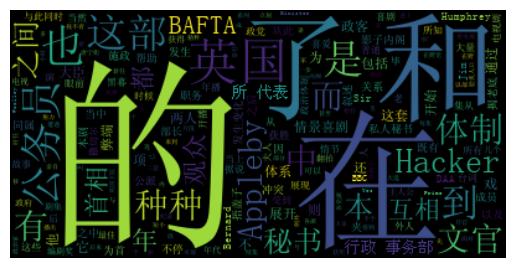

In [14]:
# 那就一起把以上的代码再重新输入一遍吧，再把字体加入
from wordcloud import WordCloud
wordcloud_cn = WordCloud(font_path="simsun.ttf").generate(text_cn_word)
%pylab inline
import matplotlib.pyplot as plt
plt.imshow(wordcloud_cn, interpolation='bilinear')
plt.axis('off')

好了！是不是感觉自己很不错呢

接下来，你还能想到哪些比较实用的改进呢？

## 给词云加上特定的形状

In [15]:
big_pic = imread('bg2.jpg')

(np.float64(-0.5), np.float64(2559.5), np.float64(2414.5), np.float64(-0.5))

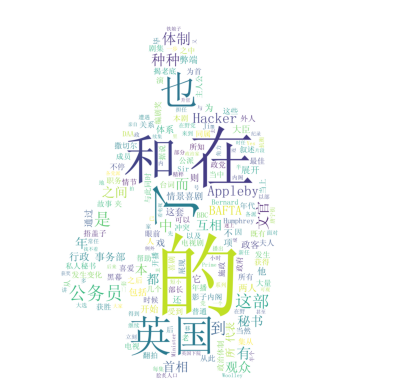

In [16]:
wordcloud_cn_x = WordCloud(mask=big_pic,width=500,height=300, background_color= 'white',scale=2.5, font_path="simsun.ttf").generate(text_cn_word)
plt.imshow(wordcloud_cn_x)
plt.axis('off')

In [17]:
wordcloud_cn_x.to_file('yes_minister_x.jpg')

## 注意：以下有wordcloud所有参数的设置，供大家作业的时候参考，修改词云效果。

In [18]:
# class wordcloud.WordCloud(font_path=None, width=400, height=200, margin=2, ranks_only=None, prefer_horizontal=0.9,mask=None, scale=1, color_func=None, max_words=200, min_font_size=4, stopwords=None, random_state=None,background_color='black', max_font_size=None, font_step=1, mode='RGB', relative_scaling=0.5, regexp=None, collocations=True,colormap=None, normalize_plurals=True)

基于以上设置作业

font_path : string //字体路径，需要展现什么字体就把该字体路径+后缀名写上，如：font_path = '黑体.ttf'

width : int (default=400) //输出的画布宽度，默认为400像素

height : int (default=200) //输出的画布高度，默认为200像素

prefer_horizontal : float (default=0.90) //词语水平方向排版出现的频率，默认 0.9 （所以词语垂直方向排版出现频率为 0.1 ）

mask : nd-array or None (default=None) //如果参数为空，则使用二维遮罩绘制词云。如果 mask 非空，设置的宽高值将被忽略，遮罩形状被 mask 取代。除全白（#FFFFFF）的部分将不会绘制，其余部分会用于绘制词云。如：bg_pic = imread('读取一张图片.png')，背景图片的画布一定要设置为白色（#FFFFFF），然后显示的形状为不是白色的其他颜色。可以用ps工具将自己要显示的形状复制到一个纯白色的画布上再保存，就ok了。

scale : float (default=1) //按照比例进行放大画布，如设置为1.5，则长和宽都是原来画布的1.5倍。

min_font_size : int (default=4) //显示的最小的字体大小

font_step : int (default=1) //字体步长，如果步长大于1，会加快运算但是可能导致结果出现较大的误差。

max_words : number (default=200) //要显示的词的最大个数

stopwords : set of strings or None //设置需要屏蔽的词，如果为空，则使用内置的STOPWORDS

background_color : color value (default=”black”) //背景颜色，如background_color='white',背景颜色为白色。

max_font_size : int or None (default=None) //显示的最大的字体大小

mode : string (default=”RGB”) //当参数为“RGBA”并且background_color不为空时，背景为透明。

relative_scaling : float (default=.5) //词频和字体大小的关联性

color_func : callable, default=None //生成新颜色的函数，如果为空，则使用 self.color_func

regexp : string or None (optional) //使用正则表达式分隔输入的文本

collocations : bool, default=True //是否包括两个词的搭配

colormap : string or matplotlib colormap, default=”viridis” //给每个单词随机分配颜色，若指定color_func，则忽略该方法。



fit_words(frequencies)  //根据词频生成词云
generate(text)  //根据文本生成词云
generate_from_frequencies(frequencies[, ...])   //根据词频生成词云
generate_from_text(text)    //根据文本生成词云
process_text(text)  //将长文本分词并去除屏蔽词（此处指英语，中文分词还是需要自己用别的库先行实现，使用上面的 fit_words(frequencies) ）
recolor([random_state, color_func, colormap])   //对现有输出重新着色。重新上色会比重新生成整个词云快很多。
to_array()  //转化为 numpy array
to_file(filename)   //输出到文件

---

## 基于参数的作业：同一段文本，三种风格

课件要求"基于以上设置作业"。这里固定文本不变，只改最影响观感的四个参数——画布尺寸、`scale`、`max_words`、`colormap`，直观看差别。

C:\Users\donganze\AppData\Local\Temp\ipykernel_55152\3437262212.py:24: UserWarning: Glyph 40664 (\N{CJK UNIFIED IDEOGRAPH-9ED8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\donganze\AppData\Local\Temp\ipykernel_55152\3437262212.py:24: UserWarning: Glyph 35748 (\N{CJK UNIFIED IDEOGRAPH-8BA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\donganze\AppData\Local\Temp\ipykernel_55152\3437262212.py:24: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\donganze\AppData\Local\Temp\ipykernel_55152\3437262212.py:24: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\donganze\AppData\Local\Temp\ipykernel_55152\3437262212.py:24: UserWarning: Glyph 40657 (\N{CJK UNIFIED IDEOGRAPH-9ED1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\donganze\AppData\Local\Temp\ipykernel_55152\3437262212.py:24: UserWarning: Glyph 2

C:\Users\donganze\.workbuddy\binaries\python\envs\default\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 40664 (\N{CJK UNIFIED IDEOGRAPH-9ED8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\donganze\.workbuddy\binaries\python\envs\default\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 35748 (\N{CJK UNIFIED IDEOGRAPH-8BA4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\donganze\.workbuddy\binaries\python\envs\default\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\donganze\.workbuddy\binaries\python\envs\default\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\donganze\.workbuddy\binaries\pytho

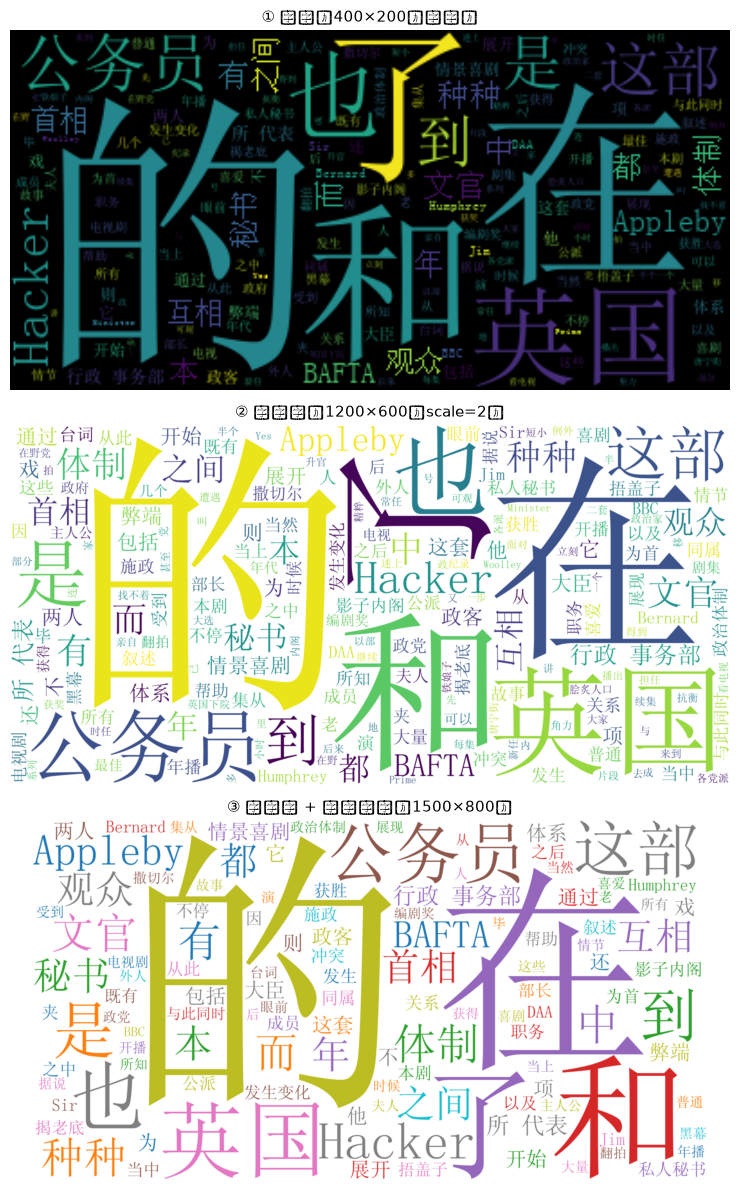

已导出 yes_minister_高清版.png  620 KB


In [19]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import os

FONT = next((p for p in ['simsun.ttf',
                         r'C:\Windows\Fonts\simsun.ttc',
                         r'C:\Windows\Fonts\msyh.ttc'] if os.path.exists(p)), None)

configs = {
    '① 默认（400×200，黑底）': dict(width=400, height=200, scale=1, background_color='black'),
    '② 大画布（1200×600，scale=2）': dict(width=1200, height=600, scale=2,
                                        background_color='white', colormap='viridis'),
    '③ 全水平 + 限制词数（1500×800）': dict(width=1500, height=800, scale=2,
                                        background_color='white', colormap='tab10',
                                        prefer_horizontal=1.0, max_words=120, min_font_size=9),
}

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
for ax, (title, kw) in zip(axes, configs.items()):
    wc = WordCloud(font_path=FONT, **kw).generate(text_cn_word)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=11)
    ax.axis('off')
plt.tight_layout()
plt.show()

# 把效果最好的一组单独导出
wc_best = WordCloud(font_path=FONT, width=1500, height=800, scale=2,
                    background_color='white', colormap='tab10',
                    prefer_horizontal=1.0, max_words=120, min_font_size=9
                   ).generate(text_cn_word)
wc_best.to_file('yes_minister_高清版.png')
print(f'已导出 yes_minister_高清版.png  {os.path.getsize("yes_minister_高清版.png") / 1024:.0f} KB')

### 小结

三组参数的差别非常直观：

- **①默认 400×200** 只有 8 万像素，字挤在一起，背景还是黑色，放在文档里几乎看不清；
- **②放大画布** 到 1200×600 并 `scale=2`，像素提升到约 288 万，字能认清了；
- **③全水平 + 限制词数** 把竖排词全部转正、词数压到 120 个、字号下限提到 9，可读性最好。

**结论：词云的"好看"不是靠换配色，而是先把像素和字号喂饱，再谈风格。** 这也解释了为什么课件里要单独强调 `width`、`height`、`scale` 这几个参数。